# FEN Piura V3 · Optimización cuántica de rutas humanitarias en IBM Quantum (hardware real)

**Caso:** distribución de ayuda a albergues durante el Fenómeno El Niño en el Bajo Piura (VRPTW con flota heterogénea).
**Quién decide:** la **QPU de IBM**. En cada ronda, QAOA elige qué combinación de rutas usar en varias *zonas* del plan; el MILP clásico solo sirve como **vara de medir**.

**Patrón Qiskit en 4 pasos**

| Paso | En este notebook |
|---|---|
| **Map** | VRPTW → rutas candidatas factibles → QUBO por zona → Hamiltoniano de Ising → circuito QAOA |
| **Optimize** | Transpilación a ISA del backend (nivel 3), conteo de compuertas 2q y **fidelidad estimada** con la calibración del día |
| **Execute** | `SamplerV2` en hardware real, **todas las zonas en un solo job**, dynamical decoupling + twirling |
| **Post-process** | Decodificar cadenas, validar restricciones, aplicar la mejor combinación y comparar contra azar y contra el óptimo |

**Localización del almacén:** el almacén actual es ficticio. El notebook evalúa sedes candidatas del Bajo Piura y el centro de gravedad de la demanda, resolviendo el ruteo completo para cada una, y propone dónde ubicarlo.

**Datos reales que entran al modelo**
- **OpenStreetMap (OSRM):** km por carretera entre almacén y albergues.
- **Open-Meteo:** lluvia del día más intenso del **Niño Costero 2017** (reanálisis) o el pronóstico de hoy. La lluvia vuelve más lentos los tramos, aumenta la incertidumbre y puede dejar albergues **solo para 4x4**.
- **Estocástico:** cada ruta tiene una **confiabilidad** (probabilidad de cumplir ventanas) estimada por Monte Carlo; las rutas poco confiables se descartan.

> ⚠️ Albergues, demandas y ventanas son **ilustrativos**. No usar para despacho real.

**Credenciales (Colab → 🔑 Secrets):** `IBM_QUANTUM_TOKEN` (API key) y, si tienes varias instancias, `IBM_QUANTUM_INSTANCE` (CRN).

## 0. Instalación

In [33]:
%pip install -q -U "numpy>=2,<3" "pandas>=2.2.3" "qiskit==2.6.1" "qiskit-ibm-runtime==0.51.0" folium requests pylatexenc
# En Colab no hace falta reiniciar; en un Python local, reinicia el kernel después de instalar.

## 1. Motor del modelo (`fen_v3.py`)
Se escribe el módulo para que el notebook sea autocontenido. En el repositorio el mismo archivo está como `fen_v3.py`.

In [6]:
"""FEN Piura V3 · optimización cuántico-híbrida en hardware IBM real.

Cambios frente a V2:
  * La QPU decide: búsqueda por vecindarios (zonas) donde QAOA en IBM Quantum
    escoge la combinación de rutas; el MILP clásico queda como referencia.
  * Todas las zonas de una ronda se envían en UN solo job (batch de circuitos).
  * Supresión de errores (dynamical decoupling + twirling) y fidelidad estimada
    del circuito ISA a partir de las calibraciones del backend.
  * Distancias por carretera reales (OSRM / OpenStreetMap) con respaldo Haversine.
  * Lluvia real (Open-Meteo): pronóstico de hoy o un día del Niño Costero 2017.
  * Confiabilidad estocástica de cada ruta (Monte Carlo de tiempos de viaje).

NO apto para despacho real: albergues, demandas y ventanas son ilustrativos.
"""
from __future__ import annotations

import itertools
import json
import math
import time
import zlib
from collections import Counter
from dataclasses import asdict, dataclass, field, replace
from pathlib import Path
from typing import Optional

import numpy as np
from scipy.optimize import Bounds, LinearConstraint, milp, minimize
from scipy.sparse import lil_matrix

SEED = 20261024
DEPOT = ("D0", -5.1945, -80.6328)
BASE_RAW = [
    ("P1", "Los Algarrobos", "Catacaos", -5.2670, -80.6760, 4, "06:30", "08:00", 3, False),
    ("P2", "Nueva Esperanza", "Cura Mori", -5.3230, -80.6640, 2, "07:00", "09:30", 3, True),
    ("P3", "El Porvenir", "El Tallán", -5.4100, -80.6830, 1, "07:00", "10:30", 2, True),
    ("P4", "Santa Rosa", "La Arena", -5.3440, -80.7110, 3, "08:00", "12:00", 2, False),
    ("P5", "Las Palmeras", "La Unión", -5.3990, -80.7420, 3, "08:00", "13:00", 2, False),
    ("P6", "San Martín", "Vice", -5.4180, -80.7790, 2, "09:00", "15:00", 1, False),
    ("P7", "Los Ceibos", "Bernal", -5.4600, -80.7430, 1, "07:00", "07:45", 3, False),
    ("P8", "Puerto Nuevo", "Sechura", -5.5580, -80.8210, 3, "10:00", "16:00", 1, False),
]
HTTP_TIMEOUT = 25


def minutes(t: str) -> int:
    h, m = map(int, t.split(":"))
    return 60 * h + m


def clock(t: float) -> str:
    if not math.isfinite(t):
        return "--:--"
    t = int(round(t))
    return f"{t // 60:02d}:{t % 60:02d}"


# ----------------------------------------------------------------------------
# Modelo de datos
# ----------------------------------------------------------------------------
@dataclass(frozen=True)
class Stop:
    id: str; name: str; region: str; lat: float; lon: float; demand: int
    start: int; end: int; priority: int; flooded: bool = False; source: str = "ficticio"


@dataclass(frozen=True)
class Vehicle:
    id: str; name: str; capacity: int; speed_kmh: float; offroad: bool


@dataclass(frozen=True)
class TripSlot:
    id: str; vehicle: str; index: int; start: int; end: int


@dataclass
class Scenario:
    name: str
    stops: dict
    vehicles: dict
    slots: list
    detours: dict                       # {(a,b) ordenado: multiplicador}; inf = tramo cerrado
    max_stops: int = 3
    start: int = 360
    end: int = 1080
    route_factor: float = 1.3          # solo para el respaldo Haversine
    priority_weight: float = 1.0
    wait_weight: float = 0.05
    road_km: Optional[dict] = None      # {(a,b): km por carretera (OSRM)}
    distance_source: str = "Haversine x1.3 (respaldo)"
    weather: dict = field(default_factory=dict)       # {punto: {lluvia_mm, mult, sigma, ...}}
    weather_source: str = "sin clima"
    depot: tuple = DEPOT                # ("D0", lat, lon) del almacén
    depot_name: str = "Almacén ficticio (Piura)"


@dataclass(frozen=True)
class Route:
    id: str; slot: str; vehicle: str; points: tuple; cost: float
    drive: float; wait: float; return_at: float; load: int; reliability: float = 1.0


def make_scenario(n: int = 8, seed: int = SEED, depot: Optional[tuple] = None,
                  depot_name: Optional[str] = None) -> Scenario:
    """8 = caso heredado de V1; 10/25/50 añaden puntos sintéticos alrededor de los 8."""
    if n not in (8, 10, 25, 50):
        raise ValueError("Tamaños previstos: 8, 10, 25 o 50")
    stops = {}
    for ident, name, region, lat, lon, d, a, b, p, flood in BASE_RAW:
        stops[ident] = Stop(ident, name, region, lat, lon, d, minutes(a), minutes(b), p, flood)
    rng = np.random.default_rng(seed)
    for k in range(9, n + 1):
        _, _, reg, lat, lon, *_ = BASE_RAW[(k - 9) % 8]
        st = Stop(f"S{k:02d}", f"Punto sintético {k}", reg,
                  lat + float(rng.uniform(-0.013, 0.013)), lon + float(rng.uniform(-0.013, 0.013)),
                  int(rng.choice([1, 1, 2])), minutes("06:00"), minutes("18:00"),
                  int(rng.integers(1, 4)), False, "sintético")
        stops[st.id] = st
    base = [Vehicle("V1", "Camión 6 t", 10, 35, False), Vehicle("V2", "Camioneta 4x4", 4, 50, True),
            Vehicle("V3", "Camión 4x4", 7, 40, True)]
    if n == 8:
        v, trips = base, 1
    elif n == 10:
        v, trips = base + [Vehicle("V4", "Camión 4x4 B", 8, 42, True)], 1
    elif n == 25:
        v, trips = base + [Vehicle("V4", "Camión 4x4 B", 8, 42, True), Vehicle("V5", "Camión 6 t B", 10, 38, False)], 2
    else:
        v = base + [Vehicle("V4", "Camión 4x4 B", 8, 42, True), Vehicle("V5", "Camión 6 t B", 10, 38, False),
                    Vehicle("V6", "Camioneta 4x4 B", 5, 50, True), Vehicle("V7", "Camión 4x4 C", 8, 40, True),
                    Vehicle("V8", "Camión 6 t C", 10, 38, False)]
        trips = 3
    slots = [TripSlot(f"{veh.id}:T{j + 1}", veh.id, j, 360 + j * int(720 / trips), 360 + (j + 1) * int(720 / trips))
             for veh in v for j in range(trips)]
    detours = {tuple(sorted(k)): val for k, val in {("P5", "P6"): 3.0, ("D0", "P8"): 1.4}.items()}
    s = Scenario(f"Bajo Piura · {n} puntos", stops, {x.id: x for x in v}, slots, detours)
    if depot is not None:
        s.depot = ("D0", float(depot[0]), float(depot[1]))
        s.depot_name = depot_name or f"Almacén ({depot[0]:.4f}, {depot[1]:.4f})"
    return s


def coords(s: Scenario, p: str) -> tuple:
    return (s.depot[1], s.depot[2]) if p == "D0" else (s.stops[p].lat, s.stops[p].lon)


def node_ids(s: Scenario) -> list:
    return ["D0"] + list(s.stops)


# ----------------------------------------------------------------------------
# Datos externos: OpenStreetMap (OSRM) y clima (Open-Meteo)
# ----------------------------------------------------------------------------
def _get_json(url: str, params: Optional[dict] = None) -> dict:
    import requests
    r = requests.get(url, params=params, timeout=HTTP_TIMEOUT,
                     headers={"User-Agent": "FEN-Piura-hackathon/3.0"})
    r.raise_for_status()
    return r.json()


def load_osrm_distances(s: Scenario, server: str = "https://router.project-osrm.org") -> Scenario:
    """Matriz de km por carretera real (red OpenStreetMap) con el servicio /table de OSRM.
    Si el servicio falla, se mantiene Haversine x1.3 y se informa la fuente."""
    ids = node_ids(s)
    coord = ";".join(f"{coords(s, i)[1]:.6f},{coords(s, i)[0]:.6f}" for i in ids)
    try:
        data = _get_json(f"{server}/table/v1/driving/{coord}", {"annotations": "distance,duration"})
        if data.get("code") != "Ok":
            raise RuntimeError(data.get("message", data.get("code")))
        dist = data["distances"]
        road = {}
        for a, i in enumerate(ids):
            for b, j in enumerate(ids):
                if i != j:
                    val = dist[a][b]
                    road[(i, j)] = (val / 1000.0) if val is not None else float("inf")
        s.road_km = road
        s.distance_source = "OSRM / OpenStreetMap (km por carretera)"
    except Exception as exc:  # noqa: BLE001 - se informa al usuario
        s.road_km = None
        s.distance_source = f"Haversine x{s.route_factor} (OSRM no disponible: {type(exc).__name__})"
    return s


def osrm_geometry(s: Scenario, seq: list, server: str = "https://router.project-osrm.org") -> Optional[list]:
    """Trazo real por calles para dibujar una ruta [(lat, lon), ...]; None si falla."""
    coord = ";".join(f"{coords(s, i)[1]:.6f},{coords(s, i)[0]:.6f}" for i in seq)
    try:
        data = _get_json(f"{server}/route/v1/driving/{coord}", {"overview": "full", "geometries": "geojson"})
        return [(lat, lon) for lon, lat in data["routes"][0]["geometry"]["coordinates"]]
    except Exception:
        return None


def _rain_to_effects(rain_day_mm: float, rain_max_mmh: float, prob: float, flood_mm: float) -> dict:
    """Supuestos (documentados, calibrables con el equipo):
    - lentitud: +50 % del tiempo de viaje con 50 mm/día o más (lineal hasta ese tope);
    - incertidumbre: sigma log-normal 0.10 en seco hasta 0.35 con lluvia intensa;
    - acceso inundado (solo 4x4) si la lluvia del día supera flood_mm."""
    level = min(max(rain_day_mm, 0.0) / 50.0, 1.0)
    return dict(lluvia_mm=round(rain_day_mm, 1), max_mm_h=round(rain_max_mmh, 1), prob=prob,
                mult=1.0 + 0.5 * level, sigma=0.10 + 0.25 * level, inundado=rain_day_mm >= flood_mm)


def load_weather(s: Scenario, mode: str = "fen2017", start_date: str = "2017-03-15",
                 end_date: str = "2017-03-31", flood_mm: float = 30.0) -> Scenario:
    """Lluvia por punto con Open-Meteo (sin API key).
    mode='pronostico': pronóstico horario de hoy (hora de Lima).
    mode='fen2017'   : reanálisis histórico; toma el día más lluvioso del rango (Niño Costero 2017).
    Solo cuenta la lluvia entre 06:00 y 18:00 (jornada de reparto)."""
    ids = node_ids(s)
    lat = ",".join(f"{coords(s, i)[0]:.4f}" for i in ids)
    lon = ",".join(f"{coords(s, i)[1]:.4f}" for i in ids)
    try:
        if mode == "pronostico":
            data = _get_json("https://api.open-meteo.com/v1/forecast",
                             dict(latitude=lat, longitude=lon, timezone="America/Lima", forecast_days=1,
                                  hourly="precipitation,precipitation_probability"))
        elif mode == "fen2017":
            data = _get_json("https://archive-api.open-meteo.com/v1/archive",
                             dict(latitude=lat, longitude=lon, timezone="America/Lima",
                                  start_date=start_date, end_date=end_date, hourly="precipitation"))
        else:
            raise ValueError("mode debe ser 'pronostico' o 'fen2017'")
        data = data if isinstance(data, list) else [data]
        times = np.array(data[0]["hourly"]["time"])
        days = np.array([t[:10] for t in times])
        hours = np.array([int(t[11:13]) for t in times])
        rain = np.array([[v or 0.0 for v in d["hourly"]["precipitation"]] for d in data])  # (puntos, horas)
        work = (hours >= 6) & (hours < 18)
        uniq = sorted(set(days))
        if mode == "fen2017":   # día con más lluvia media en la jornada
            day = max(uniq, key=lambda dd: rain[:, (days == dd) & work].sum(axis=1).mean())
        else:
            day = uniq[0]
        mask = (days == day) & work
        weather = {}
        for k, i in enumerate(ids):
            if mode == "pronostico":
                pr = [v or 0 for v, m in zip(data[k]["hourly"]["precipitation_probability"], mask) if m]
                prob = float(max(pr)) if pr else 0.0
            else:
                prob = 100.0 if rain[k, mask].sum() > 0.5 else 0.0
            weather[i] = _rain_to_effects(float(rain[k, mask].sum()), float(rain[k, mask].max(initial=0)), prob, flood_mm)
        s.weather = weather
        s.weather_source = f"Open-Meteo {'pronóstico' if mode == 'pronostico' else 'reanálisis'} · {day}"
        for i, w in weather.items():   # la lluvia puede volver un albergue solo-4x4
            if i != "D0" and w["inundado"] and not s.stops[i].flooded:
                s.stops[i] = replace(s.stops[i], flooded=True)
    except Exception as exc:  # noqa: BLE001
        s.weather = {}
        s.weather_source = f"sin clima (Open-Meteo no disponible: {type(exc).__name__})"
    return s


# ----------------------------------------------------------------------------
# Tiempos, simulación de rutas y confiabilidad estocástica
# ----------------------------------------------------------------------------
def km(s: Scenario, a: str, b: str) -> float:
    if a == b:
        return 0.0
    if s.road_km is not None and (a, b) in s.road_km:
        return s.road_km[(a, b)]
    lat1, lon1 = map(math.radians, coords(s, a))
    lat2, lon2 = map(math.radians, coords(s, b))
    h = math.sin((lat2 - lat1) / 2) ** 2 + math.cos(lat1) * math.cos(lat2) * math.sin((lon2 - lon1) / 2) ** 2
    return 2 * 6371 * math.asin(min(1, math.sqrt(h))) * s.route_factor


def weather_mult(s: Scenario, a: str, b: str) -> float:
    if not s.weather:
        return 1.0
    return max(s.weather.get(a, {}).get("mult", 1.0), s.weather.get(b, {}).get("mult", 1.0))


def leg_sigma(s: Scenario, a: str, b: str) -> float:
    if not s.weather:
        return 0.10
    return max(s.weather.get(a, {}).get("sigma", 0.10), s.weather.get(b, {}).get("sigma", 0.10))


def travel(s: Scenario, a: str, b: str, veh: str) -> float:
    return km(s, a, b) * 60 / s.vehicles[veh].speed_kmh * s.detours.get(tuple(sorted((a, b))), 1.0) * weather_mult(s, a, b)


def close_link(s: Scenario, a: str, b: str) -> Scenario:
    """Evento: tramo intransitable (puente caído, huaico). Copia el escenario."""
    out = replace(s, detours=dict(s.detours), stops=dict(s.stops))
    out.detours[tuple(sorted((a, b)))] = float("inf")
    return out


def simulate(s: Scenario, slot: TripSlot, points) -> Optional[Route]:
    """Ruta factible (tiempos esperados) o None. Ventana dura = inicio de atención <= cierre."""
    if len(points) > s.max_stops or len(set(points)) != len(points):
        return None
    v = s.vehicles[slot.vehicle]
    load = sum(s.stops[p].demand for p in points)
    if load > v.capacity or any(s.stops[p].flooded and not v.offroad for p in points):
        return None
    t = float(slot.start); dr = wait = prio = 0.0; prev = "D0"
    for p in points:
        st = s.stops[p]; dt = travel(s, prev, p, v.id)
        if not math.isfinite(dt):
            return None
        t += dt; dr += dt; wait += max(0.0, st.start - t); t = max(t, st.start)
        if t > st.end + 1e-7:
            return None
        prio += s.priority_weight * (st.priority - 1) * max(0, t - s.start) / 60
        t += 15 + 5 * st.demand; prev = p
    dt = travel(s, prev, "D0", v.id) if points else 0.0
    if not math.isfinite(dt):
        return None
    t += dt; dr += dt
    if t > slot.end + 1e-7:
        return None
    return Route(f'{slot.id}|{"-".join(points)}', slot.id, slot.vehicle, tuple(points),
                 dr + s.wait_weight * wait + prio, dr, wait, t, load)


def reliability(s: Scenario, slot: TripSlot, points, draws: int = 200, seed: int = SEED) -> float:
    """P(cumplir todas las ventanas y volver a tiempo) con tiempos de viaje log-normales
    de media igual al tiempo esperado y dispersión creciente con la lluvia."""
    rng = np.random.default_rng(seed + zlib.crc32((slot.id + "|" + "-".join(points)).encode()))
    v = slot.vehicle
    t = np.full(draws, float(slot.start)); ok = np.ones(draws, bool); prev = "D0"
    for p in list(points) + ["D0"]:
        mu, sg = travel(s, prev, p, v), leg_sigma(s, prev, p)
        t = t + mu * rng.lognormal(-sg * sg / 2, sg, draws)
        if p == "D0":
            ok &= t <= slot.end + 1e-7
        else:
            st = s.stops[p]; t = np.maximum(t, st.start); ok &= t <= st.end + 1e-7
            t = t + 15 + 5 * st.demand
        prev = p
    return float(ok.mean())


def route_pool(s: Scenario, seed: int = SEED, min_reliability: float = 0.0,
               risk_weight: float = 0.0, draws: int = 200) -> list:
    """Rutas candidatas factibles. Con risk_weight>0 se suma (1-confiabilidad)*risk_weight
    al costo y se descartan rutas con confiabilidad < min_reliability (restricción de azar)."""
    ids = list(s.stops); out = {}
    rng = np.random.default_rng(seed)
    for ix, slot in enumerate(s.slots):
        eligible = [p for p in ids if not (s.stops[p].flooded and not s.vehicles[slot.vehicle].offroad)]
        if not eligible:
            continue
        if len(ids) <= 10:
            focused = eligible
        else:
            anchors = list(s.stops)
            center = anchors[(ix * 7 + ix // len(s.vehicles)) % len(anchors)]
            nearest = sorted(eligible, key=lambda p: km(s, center, p))[:11]
            extra = list(rng.choice(eligible, size=min(4, len(eligible)), replace=False))
            focused = list(dict.fromkeys(nearest + extra))
        cands = [(p,) for p in eligible]
        for size in range(2, s.max_stops + 1):
            for group in itertools.combinations(focused, size):
                cands.extend(itertools.permutations(group))
        for pts in cands:
            r = simulate(s, slot, pts)
            if r is None:
                continue
            if risk_weight > 0 or min_reliability > 0:
                rel = reliability(s, slot, pts, draws, seed)
                if rel < min_reliability:
                    continue
                r = replace(r, reliability=rel, cost=r.cost + risk_weight * (1 - rel))
            out[r.id] = r
    return list(out.values())


def unreachable(s: Scenario, pool: list) -> list:
    covered = {p for r in pool for p in r.points}
    return [p for p in s.stops if p not in covered]


# ----------------------------------------------------------------------------
# Validación y MILP de referencia
# ----------------------------------------------------------------------------
def validate(s: Scenario, chosen: list, required=None) -> dict:
    required = set(s.stops) if required is None else set(required)
    served = list(itertools.chain.from_iterable(r.points for r in chosen))
    slots = [r.slot for r in chosen]
    slot_by_id = {sl.id: sl for sl in s.slots}
    tests = {
        "cobertura_exacta": len(served) == len(required) and set(served) == required,
        "sin_repetidos": len(served) == len(set(served)),
        "un_viaje_por_slot": len(slots) == len(set(slots)),
        "capacidad_ventanas_acceso_retorno": all(simulate(s, slot_by_id[r.slot], r.points) is not None for r in chosen),
    }
    return {"ok": all(tests.values()), "checks": tests, "atendidos": len(set(served)), "solicitudes": len(required)}


def solve_master(s: Scenario, routes: list, time_limit: float = 30.0, required=None,
                 cost_of=None) -> dict:
    """Set partitioning: cada punto exactamente una vez, cada slot <= 1 ruta.
    cost_of(route) permite otro objetivo (p. ej. 0 = solo factibilidad, o mínimo cambio)."""
    t0 = time.perf_counter()
    required = set(s.stops) if required is None else set(required)
    rr = [r for r in routes if set(r.points) <= required]
    stop_ids = sorted(required); slot_ids = sorted({r.slot for r in rr})
    if not rr or any(not any(p in r.points for r in rr) for p in stop_ids):
        return dict(status="infeasible_pool", ok=False, optimal=False, obj=None, routes=[], elapsed=time.perf_counter() - t0)
    A = lil_matrix((len(stop_ids) + len(slot_ids), len(rr)))
    si = {p: i for i, p in enumerate(stop_ids)}; sl = {x: len(stop_ids) + j for j, x in enumerate(slot_ids)}
    for j, r in enumerate(rr):
        for p in r.points:
            A[si[p], j] = 1
        A[sl[r.slot], j] = 1
    lb = np.r_[np.ones(len(stop_ids)), np.zeros(len(slot_ids))]
    c = np.asarray([(cost_of(r) if cost_of else r.cost) for r in rr], float)
    out = milp(c, integrality=np.ones(len(rr), int), bounds=Bounds(0, 1),
               constraints=LinearConstraint(A.tocsr(), lb, np.ones(len(lb))),
               options={"time_limit": time_limit, "mip_rel_gap": 0.001})
    chosen = [r for j, r in enumerate(rr) if out.x is not None and out.x[j] > 0.5]
    checks = validate(s, chosen, required)
    return dict(status=out.message, optimal=out.status == 0, ok=checks["ok"],
                obj=sum(r.cost for r in chosen) if checks["ok"] else None,
                elapsed=time.perf_counter() - t0, pool_size=len(rr), routes=chosen, validation=checks)


def plan_cost(plan: list) -> float:
    return float(sum(r.cost for r in plan))


def summary(s: Scenario, plan: list) -> dict:
    hi = [x for x in s.stops.values() if x.priority == 3]
    return dict(rutas=len(plan), costo=round(plan_cost(plan), 2),
                km=round(sum(km(s, a, b) for r in plan for a, b in zip(("D0",) + r.points, r.points + ("D0",))), 1),
                minutos_viaje=round(sum(r.drive for r in plan), 1),
                confiabilidad_min=round(min((r.reliability for r in plan), default=1.0), 3),
                prioridad_alta_atendida=f"{sum(s.stops[p].priority == 3 for r in plan for p in r.points)}/{len(hi)}")


# ----------------------------------------------------------------------------
# Vecindarios (zonas) para la QPU
# ----------------------------------------------------------------------------
def _neighborhood(pool: list, slots: tuple, req: set, incumbent: list, max_variables: int,
                  max_combos: int = 20000):
    """Opciones = rutas de los slots de la zona cuyas combinaciones (una ruta o ninguna por slot)
    cubren exactamente los puntos req. El incumbente siempre está incluido (garantiza factibilidad)."""
    per_slot = []
    for sid in slots:
        d = {}
        for r in pool:
            if r.slot == sid and set(r.points) <= req:
                d.setdefault(frozenset(r.points), []).append(r)
        per_slot.append(d)
    combos = []

    def rec(k, remaining, chosen):
        if len(combos) >= max_combos:
            return
        if k == len(slots):
            if not remaining:
                combos.append(tuple(chosen))
            return
        rec(k + 1, remaining, chosen)                       # este slot queda libre
        for key, routes in per_slot[k].items():
            if key <= remaining:
                for r in routes:
                    rec(k + 1, remaining - key, chosen + [r])

    rec(0, frozenset(req), [])
    inc_ids = {r.id for r in incumbent}
    options = list(incumbent)
    for combo in sorted(combos, key=lambda cb: sum(r.cost for r in cb)):
        have = {z.id for z in options}
        fresh = [r for r in combo if r.id not in have]
        if fresh and len(options) + len(fresh) <= max_variables:
            options.extend(fresh)
    alternatives = sum(1 for cb in combos if {r.id for r in cb} != inc_ids)
    return options, alternatives


def select_neighborhoods(s: Scenario, plan: list, pool: list, max_variables: int = 12,
                         max_neighborhoods: int = 4, slots_per_zone: int = 3, exclude=()) -> list:
    """Zonas disjuntas de `slots_per_zone` viajes (al menos uno usado) con alternativas reales.
    Cada zona es un QUBO de <= max_variables qubits; todas van en un solo job.
    `exclude`: zonas ya probadas sin mejora (para explorar otras en la siguiente ronda)."""
    used = {r.slot: r for r in plan}
    all_slots = [sl.id for sl in s.slots]
    k = min(slots_per_zone, len(all_slots))
    excl = {tuple(sorted(z)) for z in exclude}
    cands = []
    for combo in itertools.combinations(all_slots, k):
        if tuple(sorted(combo)) in excl or not any(x in used for x in combo):
            continue
        inc = [used[x] for x in combo if x in used]
        req = set(itertools.chain.from_iterable(r.points for r in inc))
        options, alt = _neighborhood(pool, combo, req, inc, max_variables)
        if alt == 0 or len(options) < 3:
            continue
        cands.append(dict(slots=combo, required=req, incumbent=inc, routes=options, alternatives=alt,
                          score=(min(alt, 50), len(req), plan_cost(inc))))
    cands.sort(key=lambda z: z["score"], reverse=True)
    chosen, taken = [], set()
    for z in cands:
        if taken.isdisjoint(z["slots"]):
            chosen.append(z); taken.update(z["slots"])
        if len(chosen) >= max_neighborhoods:
            break
    for i, z in enumerate(chosen):
        z["name"] = f"Zona {i + 1} · " + " + ".join(z["slots"])
    return chosen


# ----------------------------------------------------------------------------
# QUBO, QAOA (entrenamiento de ángulos) y circuito Qiskit
# ----------------------------------------------------------------------------
def make_qubo(neigh: dict, penalty_factor: float = 1.2) -> dict:
    """E(x) = sum c_r x_r + P sum_i (cobertura_i - 1)^2 + P sum_{mismo slot} x_r x_t.
    P = penalty_factor * costo del incumbente: cualquier cadena inválida queda por encima
    del óptimo factible (cuya existencia garantiza el incumbente), sin aplastar los costos."""
    routes = neigh["routes"]; req = neigh["required"]; n = len(routes)
    costs = np.array([r.cost for r in routes], float)
    pen = penalty_factor * max(1.0, plan_cost(neigh["incumbent"]))
    lin = costs.copy(); pair = np.zeros((n, n)); const = pen * len(req)
    for p in req:
        members = [i for i, r in enumerate(routes) if p in r.points]
        for i in members:
            lin[i] -= pen
        for i, j in itertools.combinations(members, 2):
            pair[i, j] += 2 * pen
    for i, j in itertools.combinations(range(n), 2):
        if routes[i].slot == routes[j].slot:
            pair[i, j] += pen
    scale = max(1.0, float(np.max(np.abs(lin))), float(np.max(np.abs(pair))))
    return dict(name=neigh.get("name", "zona"), routes=routes, required=req, n=n, c=const / scale,
                linear=lin / scale, pairs=pair / scale, scale=scale, penalty=pen)


def all_bits(n: int) -> np.ndarray:
    return ((np.arange(2 ** n, dtype=np.int64)[:, None] >> np.arange(n, dtype=np.int64)) & 1).astype(np.uint8)


def qubo_energy(q: dict, bits) -> np.ndarray:
    B = np.atleast_2d(bits).astype(float)
    return q["c"] + B @ q["linear"] + np.einsum("bi,ij,bj->b", B, q["pairs"], B)


def qubo_decode(q: dict, bitvec) -> dict:
    picked = [r for i, r in enumerate(q["routes"]) if bitvec[i] == 1]
    cnt = Counter(p for r in picked for p in r.points)
    ok = (all(cnt[p] == 1 for p in q["required"]) and sum(cnt.values()) == len(q["required"])
          and len({r.slot for r in picked}) == len(picked))
    return {"ok": ok, "routes": picked, "obj": sum(r.cost for r in picked) if ok else None}


def exact_subproblem(q: dict) -> float:
    vals = [d["obj"] for d in (qubo_decode(q, b) for b in all_bits(q["n"])) if d["ok"]]
    return min(vals)


def _qaoa_probs(energy, params, n, p):
    state = np.full(2 ** n, 1 / np.sqrt(2 ** n), dtype=complex)
    idx = np.arange(2 ** n)
    for layer in range(p):
        g, b = params[2 * layer: 2 * layer + 2]
        state = state * np.exp(-1j * g * energy)
        cc, ss = np.cos(b), -1j * np.sin(b)
        for bit in range(n):
            zero = idx[(idx & (1 << bit)) == 0]; one = zero + (1 << bit)
            va, vb = state[zero].copy(), state[one].copy()
            state[zero] = cc * va + ss * vb; state[one] = ss * va + cc * vb
    return np.abs(state) ** 2


def _cvar(probs, energy, alpha):
    order = np.argsort(energy); p = probs[order]; e = energy[order]
    cum = np.cumsum(p); k = min(int(np.searchsorted(cum, alpha)) + 1, len(p))
    taken = p[:k].copy(); taken[-1] -= max(0.0, cum[k - 1] - alpha)
    return float(taken @ e[:k] / alpha)


def train_angles(q: dict, p: int = 1, alpha: float = 0.25, restarts: int = 4, seed: int = SEED,
                 maxiter: int = 120) -> dict:
    """Optimiza (gamma, beta) con CVaR evaluando el estado exacto en CPU (<= 14 qubits)."""
    if q["n"] > 14:
        raise ValueError("Zona demasiado grande: usa max_variables <= 14")
    E = qubo_energy(q, all_bits(q["n"]))
    rng = np.random.default_rng(seed); best = None
    for _ in range(restarts):
        x0 = rng.uniform(0, np.pi, 2 * p)
        res = minimize(lambda a: _cvar(_qaoa_probs(E, a, q["n"], p), E, alpha), x0, method="COBYLA",
                       options={"maxiter": maxiter, "rhobeg": 0.5})
        if best is None or res.fun < best.fun:
            best = res
    return dict(params=[float(v) for v in best.x], p=p, cvar=float(best.fun))


def qaoa_circuit(q: dict, params, p: int = 1):
    """Circuito QAOA del QUBO (x = (1 - z)/2): RZ + RZZ para el costo, RX como mezclador."""
    from qiskit import QuantumCircuit
    n = q["n"]; qc = QuantumCircuit(n, name=q["name"])
    qc.h(range(n))
    P = q["pairs"]
    h = -q["linear"] / 2 - P.sum(axis=1) / 4 - P.sum(axis=0) / 4
    for layer in range(p):
        gamma, beta = params[2 * layer: 2 * layer + 2]
        for j in range(n):
            if abs(h[j]) > 1e-12:
                qc.rz(2 * gamma * h[j], j)
        for i, j in zip(*np.nonzero(np.triu(P, k=1))):
            qc.rzz(2 * gamma * P[i, j] / 4, int(i), int(j))
        for j in range(n):
            qc.rx(2 * beta, j)
    qc.measure_all()
    return qc


# ----------------------------------------------------------------------------
# IBM Quantum: conexión, ejecución por lotes y métricas de hardware
# ----------------------------------------------------------------------------
def connect_ibm(token: str, instance: Optional[str] = None, backend_name: Optional[str] = None,
                min_qubits: int = 20):
    from qiskit_ibm_runtime import QiskitRuntimeService
    service = QiskitRuntimeService(channel="ibm_quantum_platform", token=token, instance=instance or None)
    backend = (service.backend(backend_name) if backend_name
               else service.least_busy(operational=True, simulator=False, min_num_qubits=min_qubits))
    return service, backend


def two_qubit_gates(isa) -> int:
    return sum(1 for ins in isa.data if ins.operation.num_qubits == 2 and ins.operation.name != "barrier")


def estimated_fidelity(isa, backend) -> Optional[float]:
    """Probabilidad estimada de una ejecución sin errores."""
    try:
        target = backend.target
    except Exception:
        return None
    f = 1.0
    for ins in isa.data:
        name = ins.operation.name
        if name in ("barrier", "delay"):
            continue
        qargs = tuple(isa.find_bit(qb).index for qb in ins.qubits)
        try:
            err = target[name][qargs].error
        except Exception:
            err = None
        if err:
            f *= max(0.0, 1.0 - err)
    return f


def run_on_qpu(backend, circuits: list, shots: int = 4000, label: str = "", dd: bool = True,
               twirling: bool = True, opt_level: int = 3, seed: int = SEED) -> dict:
    """Transpila a ISA y envía TODAS las zonas en un solo job."""
    from qiskit.transpiler import generate_preset_pass_manager
    from qiskit_ibm_runtime import SamplerV2 as Sampler
    pm = generate_preset_pass_manager(optimization_level=opt_level, backend=backend, seed_transpiler=seed)
    isa = [pm.run(c) for c in circuits]
    sampler = Sampler(mode=backend)
    sampler.options.default_shots = shots
    if dd:
        sampler.options.dynamical_decoupling.enable = True
        sampler.options.dynamical_decoupling.sequence_type = "XpXm"
    if twirling:
        sampler.options.twirling.enable_gates = True
        sampler.options.twirling.num_randomizations = "auto"
    t0 = time.time()
    job = sampler.run(isa)
    job_id = job.job_id()
    print(f"[{label}] job enviado a {backend.name}: {job_id} · {len(isa)} circuito(s) · esperando…")
    result = job.result()
    wall = time.time() - t0
    try:
        usage = job.usage()
    except Exception:
        usage = None
    counts = [r.data.meas.get_counts() for r in result]
    circ_info = [dict(qubits=c.num_qubits, prof_logica=c.depth(), prof_isa=i.depth(), puertas_2q=two_qubit_gates(i),
                      fidelidad_estimada=estimated_fidelity(i, backend)) for c, i in zip(circuits, isa)]
    print(f"[{label}] listo en {wall:.0f} s (cola + ejecución) · uso QPU: {usage} s")
    return dict(job_id=job_id, backend=backend.name, shots=shots, wall_s=round(wall, 1), qpu_s=usage,
                counts=counts, isa=isa, circuits=circ_info, label=label)


def analyze_counts(q: dict, counts: dict) -> dict:
    total = sum(counts.values()); valid = 0; best = None; opt = exact_subproblem(q); at_opt = 0
    for bits, ct in counts.items():
        x = np.array([int(ch) for ch in bits.replace(" ", "")[::-1]], dtype=int)
        d = qubo_decode(q, x)
        if d["ok"]:
            valid += ct
            if abs(d["obj"] - opt) < 1e-9:
                at_opt += ct
            if best is None or d["obj"] < best["obj"]:
                best = d
    return dict(pct_valid=100 * valid / total, pct_optimo=100 * at_opt / total, best=best, optimo_zona=opt,
                brecha_zona_pct=None if best is None else 100 * (best["obj"] - opt) / max(abs(opt), 1e-9))


def uniform_baseline(q: dict, shots: int, seed: int = SEED) -> dict:
    rng = np.random.default_rng(seed)
    bits = rng.integers(0, 2, size=(shots, q["n"]))
    dec = [qubo_decode(q, b) for b in bits]
    ok = [d for d in dec if d["ok"]]
    opt = exact_subproblem(q)
    return dict(pct_valid=100 * len(ok) / shots,
                pct_optimo=100 * sum(abs(d["obj"] - opt) < 1e-9 for d in ok) / shots,
                best=min((d["obj"] for d in ok), default=None))


def apply_neighborhoods(s: Scenario, plan: list, zones: list, picks: list) -> list:
    new = list(plan)
    for z, pick in zip(zones, picks):
        if pick is None:
            continue
        new = [r for r in new if r.slot not in z["slots"]] + list(pick["routes"])
    if not validate(s, new)["ok"]:
        return plan
    return sorted(new, key=lambda r: r.slot)


def qpu_round(s: Scenario, plan: list, pool: list, backend, label: str, shots: int = 4000, p: int = 1,
              max_variables: int = 12, max_neighborhoods: int = 4, slots_per_zone: int = 3,
              exclude=(), seed: int = SEED):
    zones = select_neighborhoods(s, plan, pool, max_variables, max_neighborhoods, slots_per_zone, exclude)
    if not zones:
        print(f"[{label}] no hay zonas con alternativas: el plan es un óptimo local para estas zonas.")
        return plan, [], None, []
    qubos = [make_qubo(z) for z in zones]
    angles = [train_angles(q, p, seed=seed) for q in qubos]
    circuits = [qaoa_circuit(q, a["params"], p) for q, a in zip(qubos, angles)]
    run = run_on_qpu(backend, circuits, shots, label)
    rows, picks, tried = [], [], []
    for z, q, cnt, ci in zip(zones, qubos, run["counts"], run["circuits"]):
        an = analyze_counts(q, cnt); ub = uniform_baseline(q, shots, seed)
        picks.append(an["best"])
        inc = plan_cost(z["incumbent"])
        if an["best"] is None or an["best"]["obj"] >= inc - 1e-9:
            tried.append(z["slots"])
        rows.append({"etapa": label, "zona": z["name"], "qubits": q["n"], "alternativas": z["alternativas"],
                     "prof_isa": ci["prof_isa"], "puertas_2q": ci["puertas_2q"],
                     "fidelidad_estimada": None if ci["fidelidad_estimada"] is None else round(ci["fidelidad_estimada"], 3),
                     "% válidas QPU": round(an["pct_valid"], 2), "% válidas azar": round(ub["pct_valid"], 2),
                     "% óptimo QPU": round(an["pct_optimo"], 2), "% óptimo azar": round(ub["pct_optimo"], 2),
                     "costo antes": round(inc, 1),
                     "costo QPU": None if an["best" ] is None else round(an["best"]["obj"], 1),
                     "óptimo zona": round(an["optimo_zona"], 1), "job_id": run["job_id"]})
    new_plan = apply_neighborhoods(s, plan, zones, picks)
    return new_plan, rows, run, tried


def repair_minimal_change(s: Scenario, plan: list, pool: list, time_limit: float = 30.0) -> dict:
    keep = {(r.slot, r.points) for r in plan}
    required = set(s.stops) - set(unreachable(s, pool))
    return solve_master(s, pool, time_limit, required, cost_of=lambda r: 0.0 if (r.slot, r.points) in keep else 1.0)


def export_json(path, s: Scenario, plan: list, metadata: Optional[dict] = None) -> Path:
    path = Path(path); path.parent.mkdir(parents=True, exist_ok=True)
    body = {"escenario": s.name, "datos": "ilustrativos", "distancias": s.distance_source, "clima": s.weather_source,
            "resumen": summary(s, plan), "rutas": [asdict(r) for r in plan], "validacion": validate(s, plan),
            "metadata": metadata or {}}
    path.write_text(json.dumps(body, ensure_ascii=False, indent=2, default=str), encoding="utf-8")
    return path


# ----------------------------------------------------------------------------
# Localización del almacén
# ----------------------------------------------------------------------------
DEPOT_CANDIDATES = [
    ("Piura ciudad (actual)", -5.1945, -80.6328),
    ("Castilla", -5.1985, -80.6170),
    ("Catacaos", -5.2665, -80.6745),
    ("La Arena", -5.3440, -80.7085),
    ("La Unión", -5.4005, -80.7420),
    ("Vice", -5.4185, -80.7760),
    ("Sechura", -5.5575, -80.8215),
]


def demand_centroid(s: Scenario) -> tuple:
    w = np.array([x.demand * x.priority for x in s.stops.values()], float)
    lat = float(np.average([x.lat for x in s.stops.values()], weights=w))
    lon = float(np.average([x.lon for x in s.stops.values()], weights=w))
    return lat, lon


def evaluate_depots(n: int, candidates=None, weather_mode: Optional[str] = "fen2017",
                    start_date: str = "2017-03-15", end_date: str = "2017-03-31", flood_mm: float = 30.0,
                    min_reliability: float = 0.7, risk_weight: float = 60.0, use_osrm: bool = True,
                    add_centroid: bool = True, time_limit: float = 20.0, river_flood=()) -> tuple:
    candidates = list(candidates or DEPOT_CANDIDATES)
    if add_centroid:
        lat, lon = demand_centroid(make_scenario(n))
        candidates.append(("Centro de demanda (propuesto)", lat, lon))
    rows, scenarios = [], {}
    for name, lat, lon in candidates:
        s = make_scenario(n, depot=(lat, lon), depot_name=name)
        if use_osrm:
            s = load_osrm_distances(s); time.sleep(1.0)
        if weather_mode:
            s = load_weather(s, weather_mode, start_date, end_date, flood_mm)
        pool = route_pool(s, min_reliability=min_reliability, risk_weight=risk_weight)
        out = unreachable(s, pool)
        req = set(s.stops) - set(out)
        res = solve_master(s, pool, time_limit, req)
        rain = s.weather.get("D0", {}).get("lluvia_mm")
        plan = res["routes"] if res["ok"] else []
        rows.append({"candidato": name, "lat": round(lat, 4), "lon": round(lon, 4),
                     "inalcanzables": len(out) if res["ok"] else len(s.stops),
                     "costo total": round(res["obj"], 1) if res["ok"] else None,
                     "km totales": summary(s, plan)["km"] if plan else None,
                     "km medio a albergues": round(float(np.mean([km(s, "D0", p) for p in s.stops])), 1),
                     "viajes usados": len(plan),
                     "confiabilidad mín.": summary(s, plan)["confiabilidad_min"] if plan else None,
                     "lluvia almacén mm": rain,
                     "almacén inundable": bool((rain is not None and rain >= flood_mm) or name in set(river_flood)),
                     "distancias": s.distance_source})
        scenarios[name] = s
    rows.sort(key=lambda r: (r["almacén inundable"], r["inalcanzables"],
                             r["costo total"] if r["costo total" ] is not None else math.inf))
    return rows, scenarios

## 2. Configuración
Valores pensados para la demo: 25 puntos, zonas de 3 viajes con ≤ 12 qubits, 2 rondas + 1 ronda tras el evento. Consumo esperado: ~10 circuitos, del orden de 1 minuto de QPU (revisa la columna `qpu_s`).

In [7]:
from fen_v3 import *
import pandas as pd, matplotlib.pyplot as plt
from IPython.display import display

TAMANO          = 25            # 8 (caso V1), 10, 25 o 50
SHOTS           = 4000
P_QAOA          = 1             # capas QAOA (1 = circuito corto, mejor en hardware)
MAX_QUBITS      = 12            # tamaño máximo de cada zona (QUBO)
VIAJES_POR_ZONA = 3
ZONAS_POR_RONDA = 4             # circuitos por job
RONDAS          = 2
BACKEND_NOMBRE  = "ibm_kingston"   # None = el menos ocupado
CLIMA           = "fen2017"     # "fen2017" (día más lluvioso de mar-2017) | "pronostico" (hoy)
FEN_DESDE, FEN_HASTA = "2017-03-15", "2017-03-31"
UMBRAL_INUNDACION_MM = 30       # lluvia diaria a partir de la cual el albergue es solo-4x4
MIN_CONFIABILIDAD    = 0.70     # restricción de azar por ruta
PESO_RIESGO          = 60       # min-equivalentes por 100 % de riesgo de llegar tarde
ELEGIR_ALMACEN = True          # evaluar candidatos y usar el mejor; False = almacén ficticio de V2
ALMACEN_FIJO   = None          # o ("Nombre", lat, lon) para forzar una ubicación concreta
DESBORDE_RIO   = {"Catacaos"}  # candidatos en zona de desborde del río Piura (2017). Validar y completar con INDECI/ANA
SALIDAS = Path("resultados_fen_v3"); SALIDAS.mkdir(exist_ok=True)

## 3. Conexión a IBM Quantum

In [8]:
token = instancia = None
try:
    from google.colab import userdata
    token = userdata.get("IBM_QUANTUM_TOKEN")
    try:
        instancia = userdata.get("IBM_QUANTUM_INSTANCE")
    except Exception:
        instancia = None
except Exception:
    pass
if not token:
    from getpass import getpass
    token = getpass("API key de IBM Quantum: ")
service, backend = connect_ibm(token, instancia, BACKEND_NOMBRE)
del token
print("Backend:", backend.name, "| qubits:", backend.num_qubits, "| cola:", backend.status().pending_jobs, "jobs")

qiskit_runtime_service._discover_account:WARNING:2026-10-24 13:32:26,151: Loading account with the given token. A saved account will not be used.
qiskit_runtime_service.__init__:WARNING:2026-10-24 13:32:35,503: Instance was not set at service instantiation. Free and trial plan instances will be prioritized. Based on the following filters: (tags: None, region: us-east, eu-de), and available plans: (open), the available account instances are: open-instance. If you need a specific instance set it explicitly either by using a saved account with a saved default instance or passing it in directly to QiskitRuntimeService(). Alternatively, pass instance='auto' or save it to your account for auto-selection without warning.
qiskit_runtime_service.backends:WARNING:2026-10-24 13:32:35,503: Using instance: open-instance, plan: open


Backend: ibm_kingston | qubits: 156 | cola: 8 jobs


## 4. ¿Dónde ubicar el almacén? (propuesta)
El almacén de V1/V2 es ficticio. Aquí se evalúan **sedes candidatas** (centros urbanos del Bajo Piura) más el **centro de gravedad de la demanda** (paletas × prioridad). Para cada una se resuelve el **ruteo completo** con las mismas carreteras, lluvia, flota y ventanas, y se ordena por:
1. almacén fuera de zona inundable (lluvia local ≥ umbral o desborde de río marcado en `DESBORDE_RIO`),
2. menos albergues inalcanzables,
3. menor costo total de distribución.

> La ubicación ganadora es una **zona recomendada**, no un local: falta confirmar un establecimiento real (acceso pavimentado, cota segura, capacidad de almacenaje) con COER Piura / municipalidad.

,candidato,lat,lon,inalcanzables,costo total,km totales,km medio a albergues,viajes usados,confiabilidad mín.,lluvia almacén mm,almacén inundable,ahorro vs actual %
0,La Unión,-5.4005,-80.7420,0,538.9,255.6,11.6,9,0.975,26.8,False,52.4
1,La Arena,-5.3440,-80.7085,0,585.8,272.1,12.6,9,0.760,28.3,False,48.2
2,Centro de demanda (propuesto),-5.3834,-80.7212,0,601.0,286.0,13.4,9,0.900,25.3,False,46.9
3,Vice,-5.4185,-80.7760,0,629.8,306.3,14.2,9,0.985,26.7,False,44.4
4,Sechura,-5.5575,-80.8215,0,973.3,509.4,24.9,10,0.975,21.6,False,14.0
5,Castilla,-5.1985,-80.6170,0,1085.5,548.7,28.1,9,0.975,22.2,False,4.1
6,Piura ciudad (actual),-5.1945,-80.6328,0,1131.9,565.8,29.0,9,0.975,22.2,False,0.0
7,Catacaos,-5.2665,-80.6745,0,767.8,370.4,18.1,9,0.995,30.6,True,32.2


Almacén propuesto: La Unión (-5.4005, -80.742) · evaluación en 77 s


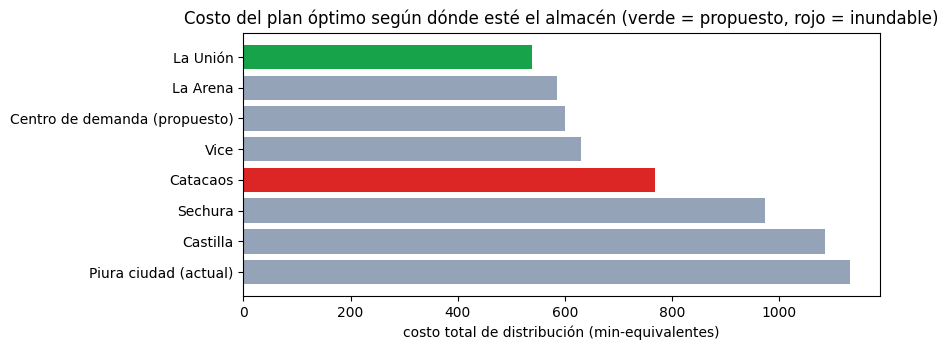

In [37]:
if ELEGIR_ALMACEN:
    import importlib
    import fen_v3
    importlib.reload(fen_v3)
    from fen_v3 import evaluate_depots
    import time
    cands = [ALMACEN_FIJO] if ALMACEN_FIJO else None
    t0 = time.time()
    ranking_alm, _ = evaluate_depots(TAMANO, cands, CLIMA, FEN_DESDE, FEN_HASTA, UMBRAL_INUNDACION_MM,
                                     MIN_CONFIABILIDAD, PESO_RIESGO, add_centroid=ALMACEN_FIJO is None,
                                     river_flood=DESBORDE_RIO)
    df_alm = pd.DataFrame(ranking_alm)
    actual = df_alm.loc[df_alm["candidato"].str.contains("actual"), "costo total"]
    if len(actual):
        df_alm["ahorro vs actual %"] = (100 * (1 - df_alm["costo total" ] / float(actual.iloc[0]))).round(1)
    display(df_alm.drop(columns=["distancias"]))
    ALMACEN = ranking_alm[0]
    print(f"Almacén propuesto: {ALMACEN['candidato']} ({ALMACEN['lat']}, {ALMACEN['lon']}) · evaluación en {time.time() - t0:.0f} s")
    d = df_alm.sort_values("costo total")
    fig, ax = plt.subplots(figsize=(9, 3.6))
    ax.barh(d["candidato"], d["costo total"],
            color=["#16a34a" if c == ALMACEN["candidato"] else ("#dc2626" if f else "#94a3b8")
                   for c, f in zip(d["candidato"], d["almacén inundable"])])
    ax.invert_yaxis(); ax.set_xlabel("costo total de distribución (min-equivalentes)")
    ax.set_title("Costo del plan óptimo según dónde esté el almacén (verde = propuesto, rojo = inundable)")
    plt.tight_layout(); plt.savefig(SALIDAS / "localizacion_almacen.png", dpi=150); plt.show()
else:
    ranking_alm = []

## 4.1 Escenario con el almacén elegido: carreteras (OSM) y lluvia (Open-Meteo)

In [38]:
if ELEGIR_ALMACEN:
    esc = make_scenario(TAMANO, depot=(ALMACEN["lat"], ALMACEN["lon"]), depot_name=ALMACEN["candidato"])
else:
    esc = make_scenario(TAMANO)
inundados_base = {p for p, x in esc.stops.items() if x.flooded}
esc = load_osrm_distances(esc)
esc = load_weather(esc, CLIMA, FEN_DESDE, FEN_HASTA, UMBRAL_INUNDACION_MM)
print("Distancias:", esc.distance_source)
print("Clima     :", esc.weather_source)
print("Almacén   :", esc.depot_name, esc.depot[1:])
tabla = pd.DataFrame([{
    "id": p.id, "zona": p.region, "demanda": p.demand, "prioridad": p.priority,
    "ventana": f"{clock(p.start)}–{clock(p.end)}",
    "km desde almacén": round(km(esc, "D0", p.id), 1),
    "lluvia mm (06–18h)": esc.weather.get(p.id, {}).get("lluvia_mm"),
    "lentitud x": esc.weather.get(p.id, {}).get("mult"),
    "solo 4x4": "sí (lluvia)" if p.flooded and p.id not in inundados_base else ("sí" if p.flooded else "no"),
} for p in esc.stops.values()])
display(tabla)

Distancias: OSRM / OpenStreetMap (km por carretera)
Clima     : Open-Meteo reanálisis · 2017-03-22
Almacén   : La Unión (-5.4005, -80.742)


,id,zona,demanda,prioridad,ventana,km desde almacén,lluvia mm (06–18h),lentitud x,solo 4x4
0,P1,Catacaos,4,3,06:30–08:00,17.8,30.6,1.306,sí (lluvia)
1,P2,Cura Mori,2,3,07:00–09:30,19.0,28.3,1.283,sí
2,P3,El Tallán,1,2,07:00–10:30,8.2,25.3,1.253,sí
3,P4,La Arena,3,2,08:00–12:00,7.8,28.3,1.283,no
4,P5,La Unión,3,2,08:00–13:00,0.2,26.8,1.268,no
5,P6,Vice,2,1,09:00–15:00,6.7,26.7,1.267,no
6,P7,Bernal,1,3,07:00–07:45,7.5,26.7,1.267,no
7,P8,Sechura,3,1,10:00–16:00,20.8,21.6,1.216,no
8,S09,Catacaos,1,2,06:00–18:00,19.6,30.6,1.306,sí (lluvia)
9,S10,Cura Mori,1,1,06:00–18:00,18.8,28.3,1.283,no


## 5. Rutas candidatas con confiabilidad estocástica
Cada ruta se simula 200 veces con tiempos de viaje log-normales (más dispersión donde llueve más). Se descartan las rutas con probabilidad de cumplir ventanas < `MIN_CONFIABILIDAD` y al resto se les suma el riesgo al costo.
Si un albergue queda sin ninguna ruta posible, se **informa como inalcanzable** (no se dibuja una ruta ficticia).

In [39]:
t0 = time.time()
pool = route_pool(esc, min_reliability=MIN_CONFIABILIDAD, risk_weight=PESO_RIESGO)
fuera = unreachable(esc, pool)
requeridos = set(esc.stops) - set(fuera)
print(f"Rutas candidatas: {len(pool)} ({time.time() - t0:.1f} s) | confiabilidad media {np.mean([r.reliability for r in pool]):.2f}")
print("Inalcanzables con estas condiciones:", fuera or "ninguno")

# Punto de partida: un plan FACTIBLE sin optimizar (el MILP solo busca factibilidad, costo 0).
inicio = solve_master(esc, pool, required=requeridos, cost_of=lambda r: 0.0)
assert inicio["ok"], "No existe plan factible: revisar ventanas, lluvia o MIN_CONFIABILIDAD"
plan = inicio["routes"]
# Referencia clásica (solo para medir la brecha al final; no alimenta a la QPU).
referencia = solve_master(esc, pool, required=requeridos)
print("Plan inicial :", summary(esc, plan))
print("Óptimo MILP  :", round(referencia["obj"], 1), "| certificado:", referencia["optimal"])

Rutas candidatas: 13624 (2.9 s) | confiabilidad media 1.00
Inalcanzables con estas condiciones: ninguno
Plan inicial : {'rutas': 10, 'costo': 1003.96, 'km': 427.1, 'minutos_viaje': 864.2, 'confiabilidad_min': 0.71, 'prioridad_alta_atendida': '8/8'}
Óptimo MILP  : 538.9 | certificado: True


## 6. Rondas cuánticas en hardware real
Cada ronda: se eligen zonas disjuntas (3 viajes, ≤ 12 qubits), se fijan los ángulos QAOA con CVaR (cálculo exacto en CPU para no gastar minutos de QPU en el bucle variacional) y **todas las zonas se envían en un solo job**. La QPU muestrea; se aplica la mejor combinación válida medida.

In [40]:
historial = [dict(etapa="inicio", costo=plan_cost(plan))]
metricas, jobs, sin_mejora = [], [], []
for k in range(1, RONDAS + 1):
    plan, filas, run, probadas = qpu_round(esc, plan, pool, backend, f"Ronda {k}", SHOTS, P_QAOA,
                                           MAX_QUBITS, ZONAS_POR_RONDA, VIAJES_POR_ZONA, exclude=sin_mejora)
    sin_mejora += probadas
    metricas += filas
    if run:
        jobs.append({k_: run[k_] for k_ in ("label", "job_id", "backend", "shots", "wall_s", "qpu_s")} | {"circuitos": len(run["counts"])})
        ultimo_run = run
    historial.append(dict(etapa=f"Ronda {k}", costo=plan_cost(plan)))
    print(f"Ronda {k}: costo {plan_cost(plan):.1f} | brecha vs MILP {100 * (plan_cost(plan) - referencia['obj']) / referencia['obj']:.1f} %")
df_m = pd.DataFrame(metricas); display(df_m)
display(pd.DataFrame(jobs))

[Ronda 1] job enviado a ibm_kingston: dbeelqnsstms73fbtv2g · 3 circuito(s) · esperando…
[Ronda 1] listo en 18 s (cola + ejecución) · uso QPU: 6 s
Ronda 1: costo 830.4 | brecha vs MILP 54.1 %
[Ronda 2] job enviado a ibm_kingston: dbeem0vsstms73fbtvh0 · 3 circuito(s) · esperando…
[Ronda 2] listo en 18 s (cola + ejecución) · uso QPU: 6 s
Ronda 2: costo 767.7 | brecha vs MILP 42.5 %


,etapa,zona,qubits,alternativas,prof_isa,puertas_2q,fidelidad_estimada,% válidas QPU,% válidas azar,% óptimo QPU,% óptimo azar,costo antes,costo QPU,óptimo zona,job_id
0,Ronda 1,Zona 1 · V1:T2 + V3:T1 + V5:T1,12,335,139,96,0.754,6.03,0.55,0.25,0.05,470.7,401.7,401.7,dbeelqnsstms73fbtv2g
1,Ronda 1,Zona 2 · V1:T1 + V4:T2 + V5:T2,12,3887,204,126,0.673,7.50,0.65,0.38,0.05,302.2,208.2,208.2,dbeelqnsstms73fbtv2g
2,Ronda 1,Zona 3 · V2:T2 + V3:T2 + V4:T1,12,59,226,132,0.679,3.70,0.42,0.35,0.05,214.0,203.4,203.4,dbeelqnsstms73fbtv2g
3,Ronda 2,Zona 1 · V1:T2 + V4:T2 + V5:T1,12,335,157,97,0.751,6.35,0.68,0.25,0.07,410.1,410.1,410.1,dbeem0vsstms73fbtvh0
4,Ronda 2,Zona 2 · V1:T1 + V3:T1 + V4:T1,12,12359,206,123,0.689,1.27,0.50,0.07,0.12,228.0,197.4,197.4,dbeem0vsstms73fbtvh0
5,Ronda 2,Zona 3 · V2:T2 + V3:T2 + V5:T2,12,407,234,149,0.638,1.80,0.30,0.07,0.05,175.2,143.1,143.1,dbeem0vsstms73fbtvh0


,label,job_id,backend,shots,wall_s,qpu_s,circuitos
0,Ronda 1,dbeelqnsstms73fbtv2g,ibm_kingston,4000,17.9,6,3
1,Ronda 2,dbeem0vsstms73fbtvh0,ibm_kingston,4000,18.2,6,3


## 7. Un circuito tal como corrió en el chip

Zona: Zona 1 · V1:T2 + V4:T2 + V5:T1 | profundidad ISA 157 | 2q 97 | operaciones {'sx': 198, 'rz': 152, 'cz': 97, 'measure': 12, 'x': 3, 'barrier': 1}


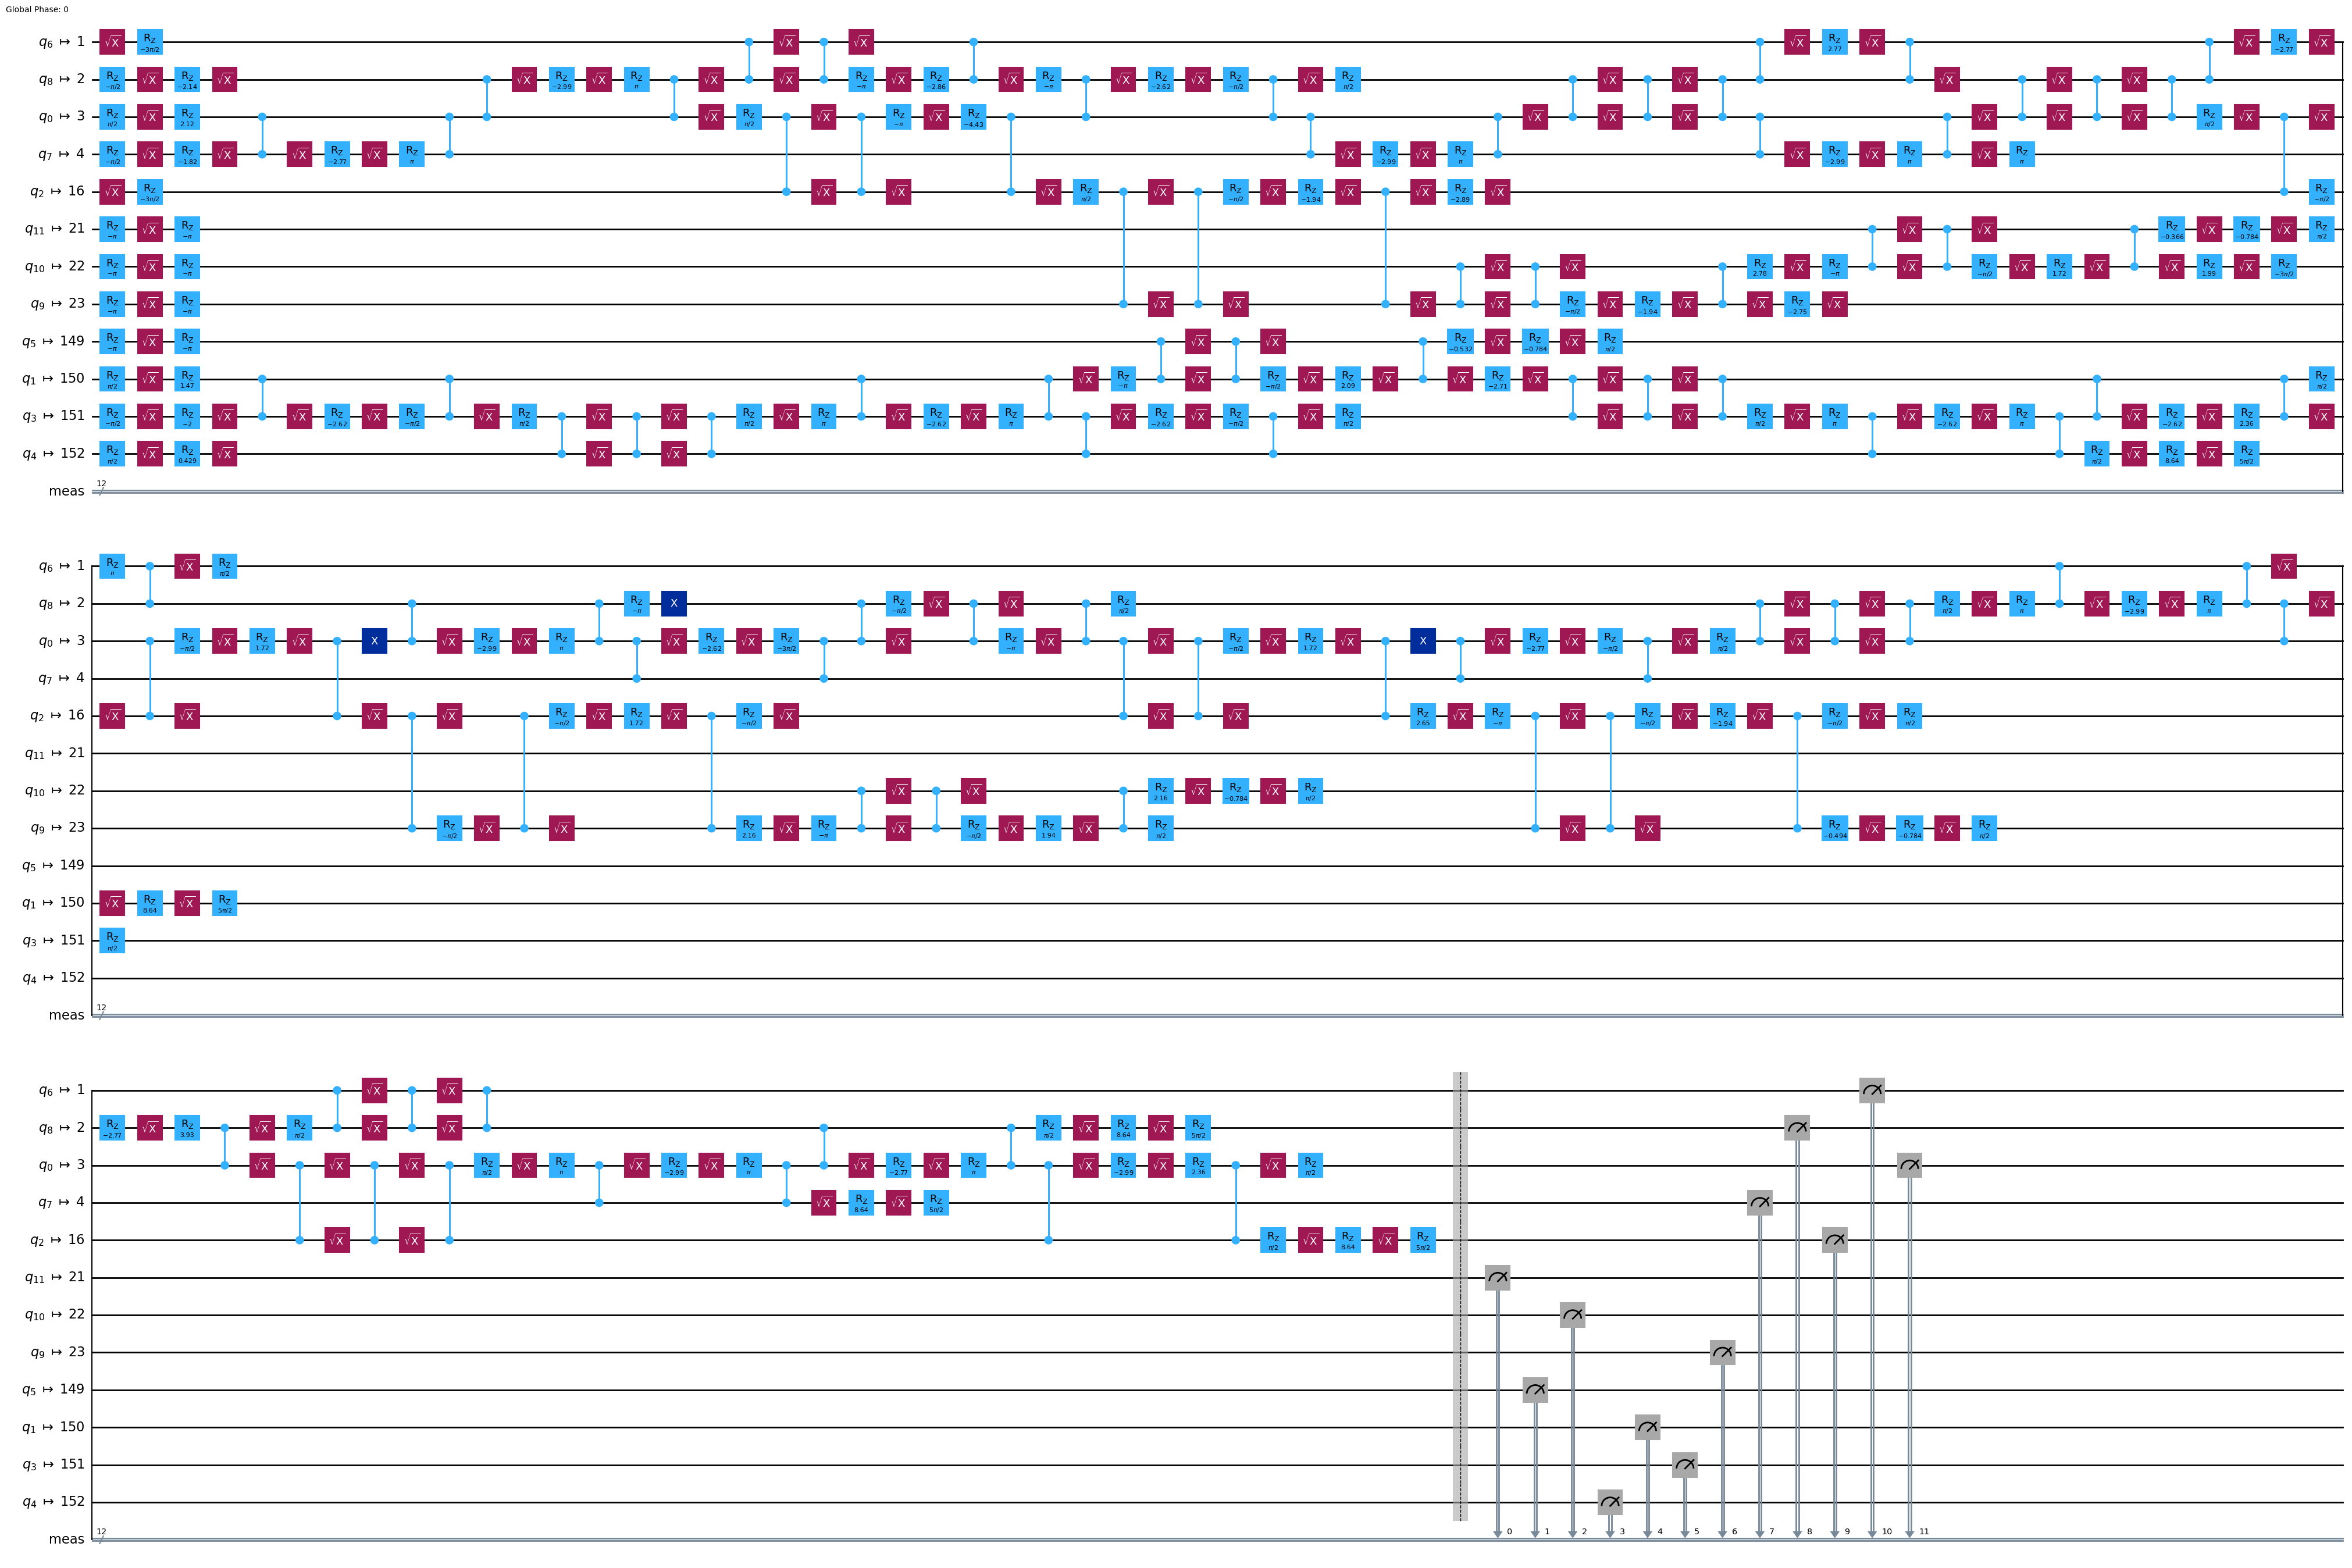

In [41]:
isa0 = ultimo_run["isa"][0]
print(f"Zona: {df_m.iloc[-len(ultimo_run['counts'])]['zona']} | profundidad ISA {isa0.depth()} | 2q {two_qubit_gates(isa0)} | operaciones {dict(isa0.count_ops())}")
display(isa0.draw(output="mpl", idle_wires=False, fold=60, style="iqp"))

## 8. Resultados: QPU vs azar vs óptimo

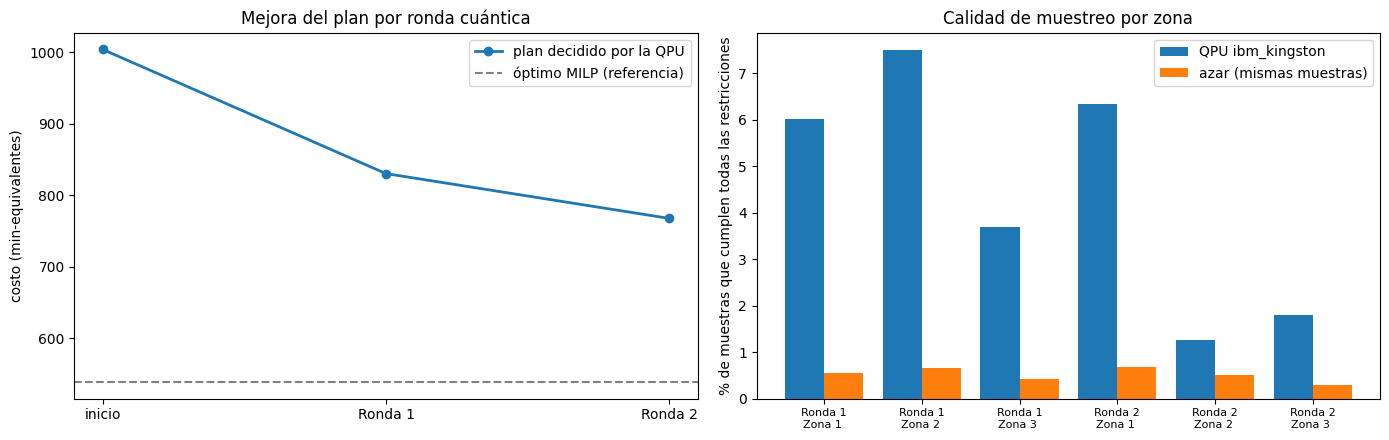

Ventaja de muestreo media (QPU / azar): 8.2 x
Validación del plan: {'ok': True, 'checks': {'cobertura_exacta': True, 'sin_repetidos': True, 'un_viaje_por_slot': True, 'capacidad_ventanas_acceso_retorno': True}, 'atendidos': 25, 'solicitudes': 25}


In [42]:
fig, (a1, a2) = plt.subplots(1, 2, figsize=(14, 4.5))
h = pd.DataFrame(historial)
a1.plot(h["etapa"], h["costo"], "o-", lw=2, label="plan decidido por la QPU")
a1.axhline(referencia["obj"], ls="--", color="gray", label="óptimo MILP (referencia)")
a1.set_ylabel("costo (min-equivalentes)"); a1.set_title("Mejora del plan por ronda cuántica"); a1.legend()
x = np.arange(len(df_m)); w = 0.4
a2.bar(x - w/2, df_m["% válidas QPU"], w, label=f"QPU {backend.name}")
a2.bar(x + w/2, df_m["% válidas azar"], w, label="azar (mismas muestras)")
a2.set_xticks(x, [f"{e}\n{z.split('·')[0]}" for e, z in zip(df_m["etapa"], df_m["zona"])], fontsize=8)
a2.set_ylabel("% de muestras que cumplen todas las restricciones"); a2.set_title("Calidad de muestreo por zona"); a2.legend()
plt.tight_layout(); plt.savefig(SALIDAS / "resultados_qpu.png", dpi=150); plt.show()
print("Ventaja de muestreo media (QPU / azar):", round((df_m["% válidas QPU"] / df_m["% válidas azar"].clip(lower=0.01)).mean(), 1), "x")
print("Validación del plan:", validate(esc, plan, requeridos))

## 9. Evento en vivo: se cierra un tramo
Se corta el tramo más crítico del plan actual (el primero de la ruta con más paradas). El sistema (1) detecta qué viajes quedan inválidos, (2) repara con el **mínimo cambio** y (3) la QPU reoptimiza en una ronda. Puedes fijar el tramo a mano en `TRAMO`.

In [43]:
TRAMO = None   # p. ej. ("P5", "P6")
if TRAMO is None:
    r_crit = max(plan, key=lambda r: (len(r.points), r.drive))
    TRAMO = ("D0", r_crit.points[0])
t0 = time.time()
evento = close_link(esc, *TRAMO)
pool_ev = route_pool(evento, min_reliability=MIN_CONFIABILIDAD, risk_weight=PESO_RIESGO)
invalidas = [r.id for r in plan if not validate(evento, [r], set(r.points))["ok"]]
rep = repair_minimal_change(evento, plan, pool_ev)
assert rep["ok"], "Sin plan factible tras el evento"
plan_ev = rep["routes"]
print(f"Tramo cerrado: {TRAMO} | viajes invalidados: {invalidas} | inalcanzables: {unreachable(evento, pool_ev) or 'ninguno'}")
print(f"Reparación clásica de mínimo cambio en {time.time() - t0:.1f} s · costo {plan_cost(plan_ev):.1f}")
plan_ev, filas_ev, run_ev, _ = qpu_round(evento, plan_ev, pool_ev, backend, "Evento", SHOTS, P_QAOA,
                                         MAX_QUBITS, ZONAS_POR_RONDA, VIAJES_POR_ZONA)
ref_ev = solve_master(evento, pool_ev, required=set(evento.stops) - set(unreachable(evento, pool_ev)))
if run_ev:
    jobs.append({k_: run_ev[k_] for k_ in ("label", "job_id", "backend", "shots", "wall_s", "qpu_s")} | {"circuitos": len(run_ev["counts"])})
display(pd.DataFrame(filas_ev))
print(f"Plan tras el evento: costo {plan_cost(plan_ev):.1f} | óptimo MILP {ref_ev['obj']:.1f} | tiempo total hasta plan nuevo {time.time() - t0:.0f} s")
print("Validación:", validate(evento, plan_ev, set(evento.stops) - set(unreachable(evento, pool_ev))))

Tramo cerrado: ('D0', 'P6') | viajes invalidados: ['V1:T2|P6-P8-S18'] | inalcanzables: ninguno
Reparación clásica de mínimo cambio en 3.0 s · costo 787.2
[Evento] job enviado a ibm_kingston: dbeem9ngdj9s73flkvk0 · 3 circuito(s) · esperando…
[Evento] listo en 13 s (cola + ejecución) · uso QPU: 6 s


,etapa,zona,qubits,alternativas,prof_isa,puertas_2q,fidelidad_estimada,% válidas QPU,% válidas azar,% óptimo QPU,% óptimo azar,costo antes,costo QPU,óptimo zona,job_id
0,Evento,Zona 1 · V1:T2 + V4:T2 + V5:T1,12,167,128,83,0.764,11.20,0.82,0.28,0.03,429.5,422.0,422.0,dbeem9ngdj9s73flkvk0
1,Evento,Zona 2 · V3:T1 + V4:T1 + V5:T2,12,395,122,66,0.807,17.62,1.23,0.42,0.07,223.0,223.0,223.0,dbeem9ngdj9s73flkvk0
2,Evento,Zona 3 · V1:T1 + V2:T2 + V3:T2,12,3147,231,137,0.679,3.85,0.35,0.30,0.03,117.5,106.8,106.8,dbeem9ngdj9s73flkvk0


Plan tras el evento: costo 768.9 | óptimo MILP 538.9 | tiempo total hasta plan nuevo 24 s
Validación: {'ok': True, 'checks': {'cobertura_exacta': True, 'sin_repetidos': True, 'un_viaje_por_slot': True, 'capacidad_ventanas_acceso_retorno': True}, 'atendidos': 25, 'solicitudes': 25}


## 10. Mapa con calles reales y cronograma

In [44]:
import folium
from folium.plugins import AntPath
# Colores neón de alto contraste (se leen sobre satélite y sobre calles)
colores = ["#00E5FF", "#FF1744", "#FFEA00", "#76FF03", "#FF00E5", "#FF9100", "#2979FF", "#1DE9B6", "#F50057", "#C6FF00"]
m = folium.Map(location=[-5.37, -80.72], zoom_start=10, tiles=None)
folium.TileLayer("https://server.arcgisonline.com/ArcGIS/rest/services/World_Imagery/MapServer/tile/{z}/{y}/{x}",
                 attr="Tiles © Esri — Maxar, Earthstar Geographics", name="Satélite").add_to(m)
folium.TileLayer("https://server.arcgisonline.com/ArcGIS/rest/services/World_Street_Map/MapServer/tile/{z}/{y}/{x}",
                 attr="Tiles © Esri — Esri, HERE, Garmin, © OpenStreetMap contributors", name="Calles").add_to(m)

# Rutas: borde oscuro grueso + línea de color animada (muestra el sentido de recorrido)
leyenda = []
for k, r in enumerate(plan_ev):
    col = colores[k % len(colores)]
    seq = ["D0", *r.points, "D0"]
    geo = osrm_geometry(evento, seq) or [coords(evento, x) for x in seq]
    capa = folium.FeatureGroup(name=f"{r.slot} · {evento.vehicles[r.vehicle].name}")
    folium.PolyLine(geo, color="#111111", weight=9, opacity=0.9).add_to(capa)
    AntPath(geo, color=col, pulse_color="#FFFFFF", weight=5, opacity=1, delay=1200,
            tooltip=f"{r.slot} · {' → '.join(seq)} · {r.load} pal. · confiabilidad {r.reliability:.0%}").add_to(capa)
    capa.add_to(m)
    leyenda.append((col, f"{r.slot} {evento.vehicles[r.vehicle].name}: {' → '.join(r.points)}"))

# Tramo cerrado: rojo grueso discontinuo con borde blanco
a, b = TRAMO
folium.PolyLine([coords(evento, a), coords(evento, b)], color="#FFFFFF", weight=10, opacity=0.9).add_to(m)
folium.PolyLine([coords(evento, a), coords(evento, b)], color="#D50000", weight=6, dash_array="10 8",
                tooltip=f"TRAMO CERRADO {a}–{b}").add_to(m)

# Albergues: color por prioridad, borde blanco, etiqueta con el id; azul = solo 4x4
prio_col = {3: "#FF1744", 2: "#FF9100", 1: "#FFEA00"}
for p in evento.stops.values():
    w = evento.weather.get(p.id, {})
    folium.CircleMarker([p.lat, p.lon], radius=6 + 2 * p.demand, color="#2979FF" if p.flooded else "#FFFFFF", weight=3,
                        fill=True, fill_color=prio_col[p.priority], fill_opacity=1,
                        tooltip=f"{p.id} {p.region} · prioridad {p.priority} · {clock(p.start)}–{clock(p.end)} · "
                                f"lluvia {w.get('lluvia_mm', '-')} mm{' · SOLO 4x4' if p.flooded else ''}").add_to(m)
    folium.Marker([p.lat, p.lon], icon=folium.DivIcon(
        html=f'<div style="font:700 11px sans-serif;color:#fff;text-shadow:0 0 3px #000,0 0 3px #000;'
             f'transform:translate(12px,-8px)">{p.id}</div>')).add_to(m)
# Candidatos evaluados (gris) y almacén elegido (negro)
for r_ in globals().get("ranking_alm", []):
    if r_["candidato"] != evento.depot_name:
        folium.CircleMarker([r_["lat"], r_["lon"]], radius=7, color="#FFFFFF", weight=2, fill=True, fill_color="#616161",
                            fill_opacity=0.9, tooltip=f"Candidato: {r_['candidato']} · costo {r_['costo total']}").add_to(m)
folium.Marker([evento.depot[1], evento.depot[2]], tooltip=f"Almacén propuesto: {evento.depot_name}",
              icon=folium.Icon(color="black", icon="home")).add_to(m)

# Leyenda fija
filas_ley = "".join(f'<div><span style="display:inline-block;width:22px;height:5px;background:{c};margin-right:6px;'
                    f'vertical-align:middle;border:1px solid #000"></span>{t}</div>' for c, t in leyenda)
html = f'''<div style="position:fixed;bottom:18px;left:18px;z-index:9999;background:rgba(17,17,17,.85);color:#fff;
 padding:10px 12px;border-radius:8px;font:12px sans-serif;max-width:360px;line-height:1.5">
 <b>Plan decidido por la QPU ({backend.name})</b><div>⌂ almacén: {evento.depot_name} · ● gris = otros candidatos</div>{filas_ley}
 <div style="margin-top:6px">● <span style="color:#FF1744">prioridad alta</span> · <span style="color:#FF9100">media</span> ·
 <span style="color:#FFEA00">baja</span> · borde <span style="color:#2979FF">azul</span> = solo 4x4</div>
 <div><span style="color:#D50000">- - -</span> tramo cerrado</div></div>'''
m.get_root().html.add_child(folium.Element(html))
_lat = [x.lat for x in evento.stops.values()] + [evento.depot[1]]; _lon = [x.lon for x in evento.stops.values()] + [evento.depot[2]]
m.fit_bounds([[min(_lat) - 0.02, min(_lon) - 0.02], [max(_lat) + 0.02, max(_lon) + 0.02]])
folium.LayerControl(collapsed=False).add_to(m)
m.save(str(SALIDAS / "mapa_plan.html")); display(m)

filas = []
slot_by = {s_.id: s_ for s_ in evento.slots}
for r in plan_ev:
    t, prev = slot_by[r.slot].start, "D0"
    for p in r.points:
        t += travel(evento, prev, p, r.vehicle); st = evento.stops[p]; ini = max(t, st.start)
        filas.append({"viaje": r.slot, "albergue": p, "llegada": clock(t), "ventana": f"{clock(st.start)}–{clock(st.end)}",
                      "inicio": clock(ini), "prioridad": st.priority, "confiabilidad ruta": f"{r.reliability:.0%}"})
        t, prev = ini + 15 + 5 * st.demand, p
display(pd.DataFrame(filas))

,viaje,albergue,llegada,ventana,inicio,prioridad,confiabilidad ruta
0,V1:T1,S21,06:02,06:00–18:00,06:02,3,100%
1,V1:T1,S13,06:26,06:00–18:00,06:26,2,100%
2,V1:T1,P5,06:49,08:00–13:00,08:00,2,100%
3,V1:T2,S18,12:41,06:00–18:00,12:41,3,99%
4,V1:T2,P6,14:02,09:00–15:00,14:02,1,99%
5,V1:T2,P8,15:10,10:00–16:00,15:10,1,99%
6,V2:T1,S14,06:09,06:00–18:00,06:09,2,100%
7,V2:T2,S25,12:28,06:00–18:00,12:28,2,100%
8,V3:T1,P1,06:35,06:30–08:00,06:35,3,100%
9,V3:T1,S12,07:34,06:00–18:00,07:34,2,100%


## 11. Generar evidencias

In [45]:
meta = dict(version="FEN-Piura-V3", almacen=dict(nombre=esc.depot_name, lat=esc.depot[1], lon=esc.depot[2]),
            ranking_almacen=ranking_alm, backend=backend.name, shots=SHOTS, p=P_QAOA, max_qubits=MAX_QUBITS,
            clima=esc.weather_source, distancias=esc.distance_source, jobs=jobs,
            metricas=metricas + filas_ev, historial=historial, tramo_cerrado=TRAMO,
            optimo_milp=referencia["obj"], optimo_milp_evento=ref_ev["obj"])
export_json(SALIDAS / "evidencia_v3.json", evento, plan_ev, meta)
pd.DataFrame(metricas + filas_ev).to_csv(SALIDAS / "metricas_qpu.csv", index=False)
print("QPU total (s):", sum(j["qpu_s"] or 0 for j in jobs), "| jobs:", [j["job_id"] for j in jobs])
print("Archivos:", [p.name for p in SALIDAS.iterdir()])

QPU total (s): 18 | jobs: ['dbeelqnsstms73fbtv2g', 'dbeem0vsstms73fbtvh0', 'dbeem9ngdj9s73flkvk0']
Archivos: ['mapa_plan.html', 'metricas_qpu.csv', 'localizacion_almacen.png', 'resultados_qpu.png', 'evidencia_v3.json']


## Cómo leer los resultados
- **% válidas QPU vs azar:** cuántas veces más que el azar el chip encuentra combinaciones que cumplen todo. Es la evidencia de que el circuito aprende la estructura del problema.
- **Costo por ronda vs MILP:** cuánto se acerca el plan decidido por la QPU al óptimo clásico. No se afirma ventaja cuántica: se mide la frontera.
- **Fidelidad estimada:** con la calibración del día, qué fracción de ejecuciones del circuito saldría sin errores; explica por qué las zonas se mantienen en ≤ 12 qubits.
- **Recuperar un job** si Colab se desconecta: `service.job("<job_id>").result()`.